# CodeAlpha Data Science Internship
## Task 2: Unemployment Analysis with Python

### Project Overview
This project explores historical unemployment data for India, with a focus on changes around the COVID-19 period. It includes data cleaning, exploratory data analysis, visualizations, regional comparisons, and evidence-based observations.

**Important:** The dataset used in this notebook covers a historical period around 2019–2020. It should not be interpreted as current unemployment statistics.

## 1. Import libraries

We use Pandas and NumPy for data handling, and Matplotlib and Seaborn for visualizations.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## 2. Load the dataset

The cell below attempts to load a public copy of the commonly used "Unemployment in India" dataset. If the online link is unavailable, upload the CSV file when prompted.

The expected dataset includes columns such as `Region`, `Date`, `Estimated Unemployment Rate (%)`, `Estimated Employed`, `Estimated Labour Participation Rate (%)`, and sometimes `Area`.

In [2]:
# Try to load the dataset from a public GitHub repository.
# If this fails, upload "Unemployment in India.csv" from your computer.
data_url = "https://raw.githubusercontent.com/SRC-co/CodeAlpha_Unemployment_Analysis_Python/main/Unemployment%20in%20India.csv"

try:
    df = pd.read_csv(data_url)
    print("Dataset loaded from the online source.")
except Exception as e:
    print("Online loading failed. Please upload the CSV file.")
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("No file uploaded. Please upload the unemployment CSV dataset.")
    file_name = next(iter(uploaded))
    df = pd.read_csv(file_name)

print("Dataset loaded successfully.")
display(df.head())

Dataset loaded from the online source.
Dataset loaded successfully.


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## 3. Inspect and clean the data

First inspect the dataset, remove extra spaces from column names and text values, remove duplicate records, and convert the date column to datetime format. We preserve missing values until we understand their extent.

In [3]:
print("Original shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# Clean whitespace from column names and text values
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].astype("string").str.strip()

# Find likely date column
date_col = next((c for c in df.columns if c.strip().lower() == "date"), None)
if date_col:
    df[date_col] = pd.to_datetime(df[date_col], dayfirst=True, errors="coerce")

# Convert likely numeric columns
for col in df.columns:
    if any(term in col.lower() for term in ["rate", "employed", "participation"]):
        df[col] = pd.to_numeric(df[col], errors="coerce")

duplicates = df.duplicated().sum()
print("Duplicate rows found:", duplicates)
df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing values"))

print("\nData types and summary:")
df.info()
display(df.describe(include="all").T)

Original shape: (768, 7)

Column names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']
Duplicate rows found: 27
Shape after removing duplicates: (741, 7)

Missing values:


,Missing values
Region,1
Date,1
Frequency,1
Estimated Unemployment Rate (%),1
Estimated Employed,1
Estimated Labour Participation Rate (%),1
Area,1



Data types and summary:
<class 'pandas.core.frame.DataFrame'>
Index: 741 entries, 0 to 753
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    string        
 1   Date                                     740 non-null    datetime64[ns]
 2   Frequency                                740 non-null    string        
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Estimated Employed                       740 non-null    float64       
 5   Estimated Labour Participation Rate (%)  740 non-null    float64       
 6   Area                                     740 non-null    string        
dtypes: datetime64[ns](1), float64(3), string(3)
memory usage: 46.3 KB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Region,740,28,Andhra Pradesh,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,740,NaN,NaN,NaN,2019-12-12 18:36:58.378378496,2019-05-31 00:00:00,2019-08-31 00:00:00,2019-11-30 00:00:00,2020-03-31 00:00:00,2020-06-30 00:00:00,NaN
Frequency,740,1,Monthly,740,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Estimated Unemployment Rate (%),740.0,NaN,NaN,NaN,11.787946,0.0,4.6575,8.35,15.8875,76.74,10.721298
Estimated Employed,740.0,NaN,NaN,NaN,7204460.025676,49420.0,1190404.5,4744178.5,11275489.5,45777509.0,8087988.429458
Estimated Labour Participation Rate (%),740.0,NaN,NaN,NaN,42.630122,13.33,38.0625,41.16,45.505,72.57,8.111094
Area,740,2,Urban,381,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Identify the unemployment-rate column

Dataset versions can differ slightly in their column names. This cell locates the unemployment-rate column by name and checks that the expected columns are available.

In [4]:
rate_col = next(
    (c for c in df.columns if "unemployment" in c.lower() and "rate" in c.lower()),
    None
)
region_col = next((c for c in df.columns if c.lower() in ["region", "state"]), None)
area_col = next((c for c in df.columns if c.lower() == "area"), None)

if rate_col is None:
    raise ValueError(
        "Could not identify the unemployment-rate column. "
        f"Available columns: {df.columns.tolist()}"
    )

if date_col is None:
    raise ValueError("Could not identify a Date column in this dataset.")

df = df.dropna(subset=[rate_col, date_col]).copy()
df = df.sort_values(date_col)

print("Date column:", date_col)
print("Unemployment-rate column:", rate_col)
print("Region column:", region_col)
print("Area column:", area_col)
print("Date range:", df[date_col].min().date(), "to", df[date_col].max().date())
print("Cleaned dataset shape:", df.shape)

Date column: Date
Unemployment-rate column: Estimated Unemployment Rate (%)
Region column: Region
Area column: Area
Date range: 2019-05-31 to 2020-06-30
Cleaned dataset shape: (740, 7)


## 5. Overall unemployment trend over time

The dataset may contain several rows per date (for different regions or areas). We calculate the average unemployment rate for each date to create an overall trend. This is a simple unweighted average across available records, not an official national estimate.

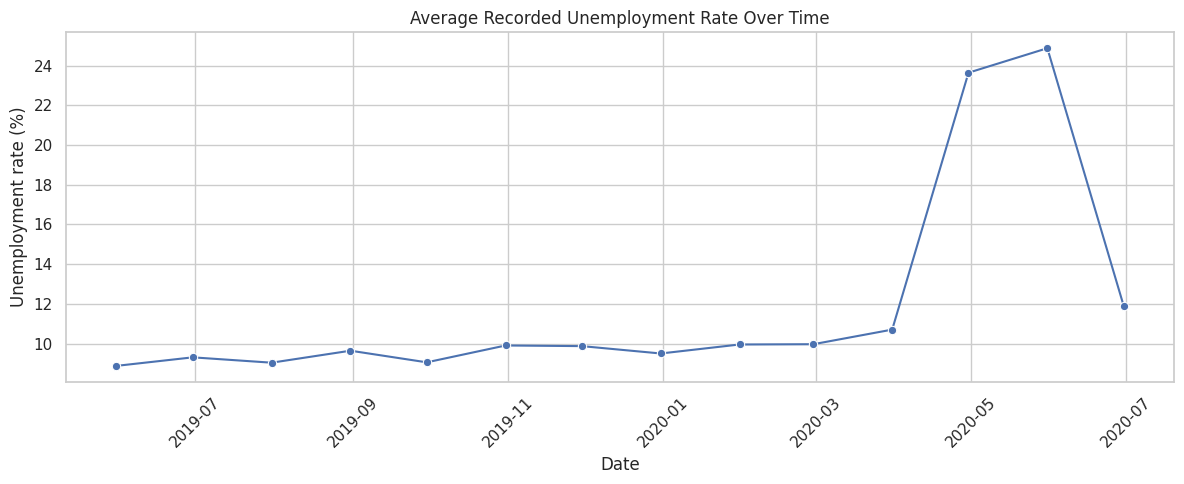

,Date,Estimated Unemployment Rate (%)
0,2019-05-31,8.874259
1,2019-06-30,9.303333
2,2019-07-31,9.033889
3,2019-08-31,9.637925
4,2019-09-30,9.051731


In [5]:
overall_trend = df.groupby(date_col, as_index=False)[rate_col].mean()

plt.figure(figsize=(12, 5))
sns.lineplot(data=overall_trend, x=date_col, y=rate_col, marker="o")
plt.title("Average Recorded Unemployment Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Unemployment rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(overall_trend.head())

## 6. Explore the COVID-19 period

For a descriptive comparison, we use:
- **Pre-COVID reference period:** dates before 1 March 2020
- **COVID period:** 1 March 2020 onward within the available dataset

This is a simplified comparison, not proof that COVID-19 alone caused every observed change. Other economic and data-collection factors may also matter.

,Period,Average unemployment rate (%),Median unemployment rate (%),Number of records
0,COVID period (Mar 2020 onward),17.77,14.52,204
1,Pre-COVID (before Mar 2020),9.51,7.12,536


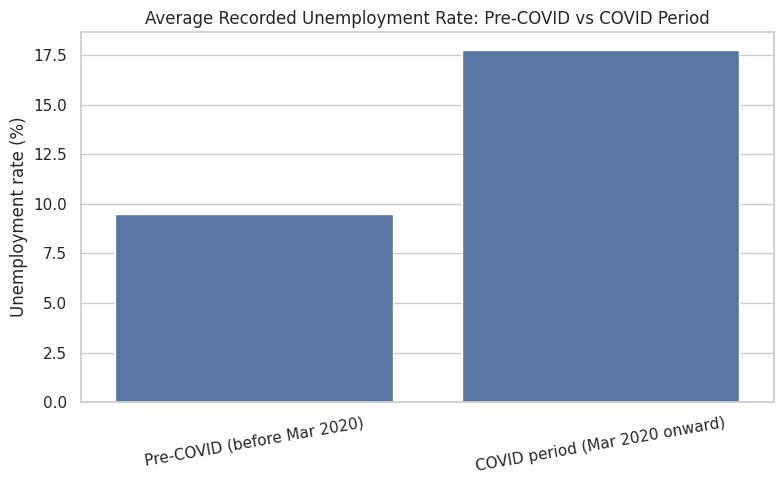

In [6]:
covid_start = pd.Timestamp("2020-03-01")
df["Period"] = np.where(df[date_col] < covid_start, "Pre-COVID (before Mar 2020)", "COVID period (Mar 2020 onward)")

period_summary = df.groupby("Period")[rate_col].agg(["mean", "median", "count"]).reset_index()
period_summary = period_summary.rename(columns={
    "mean": "Average unemployment rate (%)",
    "median": "Median unemployment rate (%)",
    "count": "Number of records"
})
display(period_summary.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="Period", y=rate_col, errorbar=None)
plt.title("Average Recorded Unemployment Rate: Pre-COVID vs COVID Period")
plt.xlabel("")
plt.ylabel("Unemployment rate (%)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

## 7. Monthly pattern analysis

We calculate the average rate by calendar month to explore possible monthly patterns. Because this dataset covers a short historical period and includes the pandemic shock, these averages should not be treated as reliable evidence of recurring seasonality.

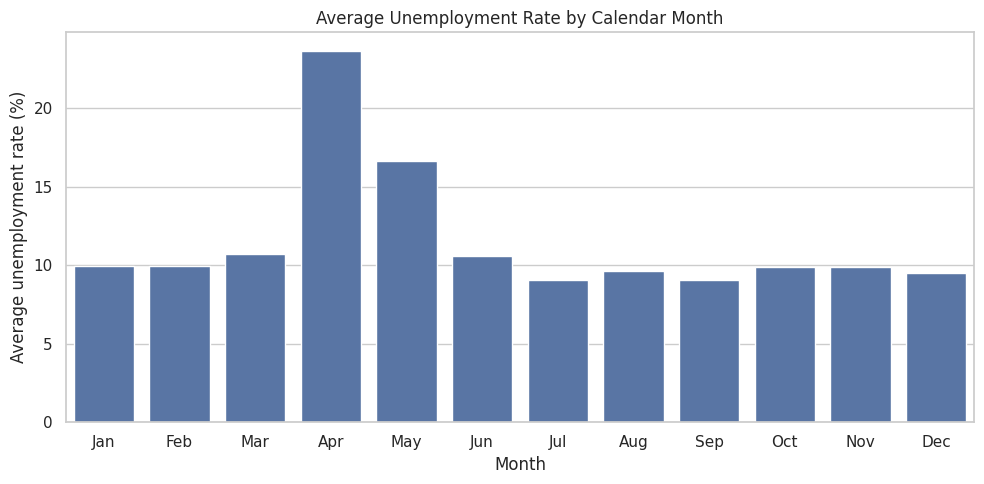

,Average unemployment rate (%)
Month number,
1,9.95
2,9.96
3,10.70
4,23.64
5,16.65
6,10.55
7,9.03
8,9.64
9,9.05


In [7]:
df["Month Number"] = df[date_col].dt.month
monthly_summary = df.groupby("Month Number")[rate_col].mean().reindex(range(1, 13))

month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(10, 5))
sns.barplot(x=month_labels, y=monthly_summary.values)
plt.title("Average Unemployment Rate by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average unemployment rate (%)")
plt.tight_layout()
plt.show()

display(monthly_summary.rename_axis("Month number").to_frame("Average unemployment rate (%)").round(2))

## 8. Region-wise comparison

If the dataset includes a region/state column, compare average recorded unemployment rates across regions. These are averages over the available observations and may be influenced by differences in the dates or number of records available for each region.

10 regions with the highest average recorded rates:


,Average unemployment rate (%),Number of records
Region,,
Tripura,28.35,28
Haryana,26.28,28
Jharkhand,20.58,28
Bihar,18.92,28
Himachal Pradesh,18.54,28
Delhi,16.50,28
Jammu & Kashmir,16.19,21
Chandigarh,15.99,12
Rajasthan,14.06,28


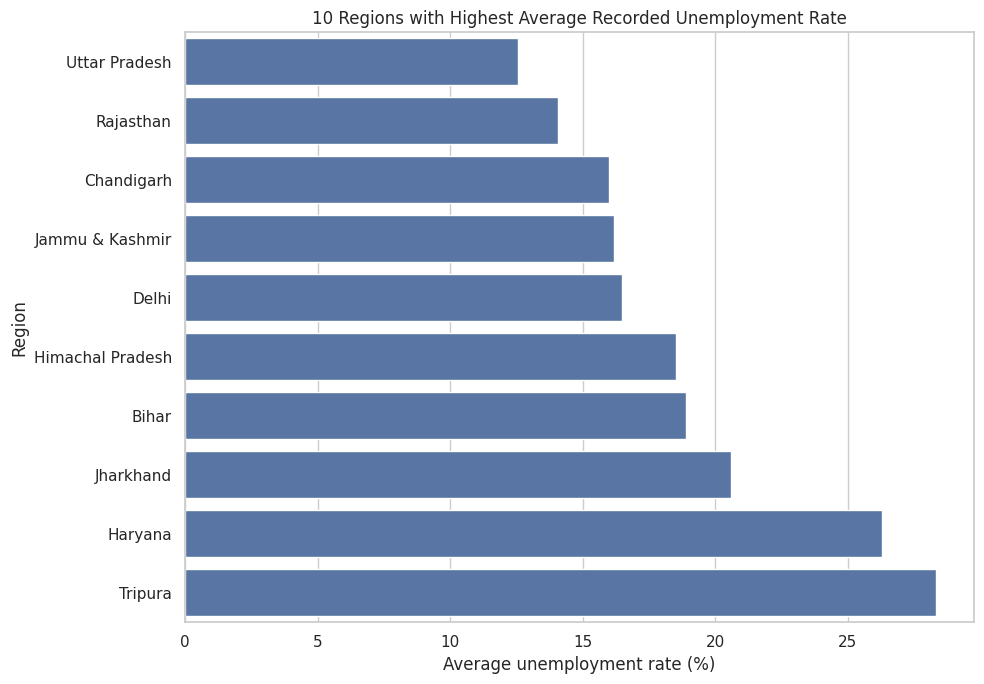

In [8]:
if region_col:
    region_summary = (
        df.groupby(region_col)[rate_col]
          .agg(["mean", "count"])
          .rename(columns={"mean": "Average unemployment rate (%)", "count": "Number of records"})
          .sort_values("Average unemployment rate (%)", ascending=False)
    )

    print("10 regions with the highest average recorded rates:")
    display(region_summary.head(10).round(2))

    plt.figure(figsize=(10, 7))
    top_regions = region_summary.head(10).sort_values("Average unemployment rate (%)")
    sns.barplot(data=top_regions, x="Average unemployment rate (%)", y=top_regions.index)
    plt.title("10 Regions with Highest Average Recorded Unemployment Rate")
    plt.xlabel("Average unemployment rate (%)")
    plt.ylabel("Region")
    plt.tight_layout()
    plt.show()
else:
    print("No region/state column found; skipping regional comparison.")

## 9. Urban vs rural comparison

If an `Area` column exists, compare urban and rural records over time. If this dataset version does not include an area column, the cell will explain that the comparison is unavailable.

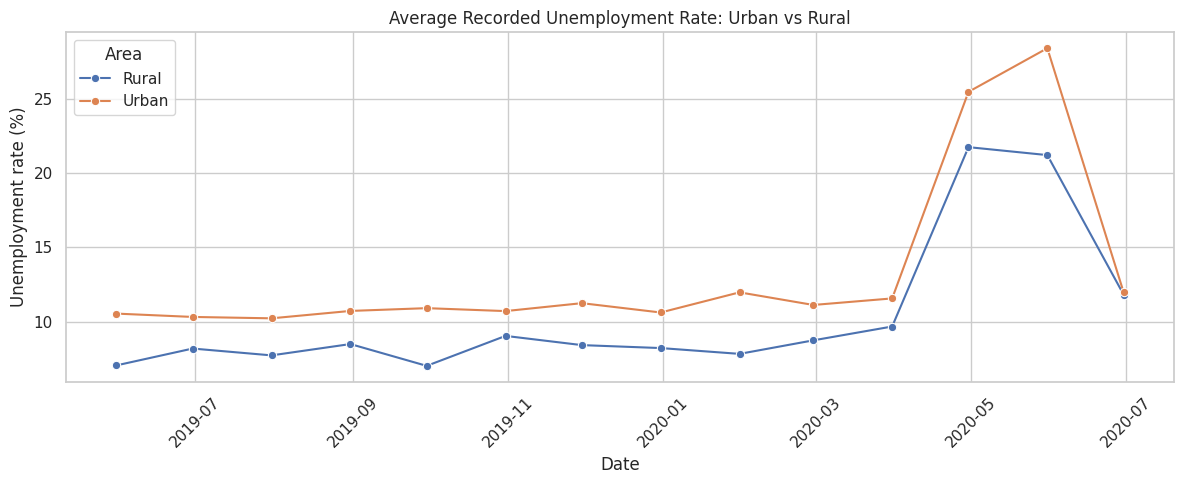

,Date,Area,Estimated Unemployment Rate (%)
0,2019-05-31,Rural,7.068077
1,2019-05-31,Urban,10.551429
2,2019-06-30,Rural,8.201154
3,2019-06-30,Urban,10.326786
4,2019-07-31,Rural,7.741923


In [9]:
if area_col:
    area_trend = df.groupby([date_col, area_col], as_index=False)[rate_col].mean()

    plt.figure(figsize=(12, 5))
    sns.lineplot(data=area_trend, x=date_col, y=rate_col, hue=area_col, marker="o")
    plt.title("Average Recorded Unemployment Rate: Urban vs Rural")
    plt.xlabel("Date")
    plt.ylabel("Unemployment rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    display(area_trend.head())
else:
    print("This dataset version does not contain an Area column, so urban/rural comparison is skipped.")

## 10. Key findings generated from the data

The following summary calculates the observed minimum and maximum rates and the average rates in the two periods. Use the results from your actual run when writing the final interpretation.

In [10]:
print("Number of records analyzed:", len(df))
print("Overall average recorded unemployment rate:", round(df[rate_col].mean(), 2), "%")
print("Lowest recorded rate:", round(df[rate_col].min(), 2), "%")
print("Highest recorded rate:", round(df[rate_col].max(), 2), "%")

max_row = df.loc[df[rate_col].idxmax()]
min_row = df.loc[df[rate_col].idxmin()]

print("\nDate of highest recorded rate:", max_row[date_col].date())
if region_col:
    print("Region with highest recorded rate:", max_row[region_col])
print("Date of lowest recorded rate:", min_row[date_col].date())
if region_col:
    print("Region with lowest recorded rate:", min_row[region_col])

print("\nAverage rate by period:")
display(df.groupby("Period")[rate_col].mean().round(2).to_frame("Average unemployment rate (%)"))

Number of records analyzed: 740
Overall average recorded unemployment rate: 11.79 %
Lowest recorded rate: 0.0 %
Highest recorded rate: 76.74 %

Date of highest recorded rate: 2020-04-30
Region with highest recorded rate: Puducherry
Date of lowest recorded rate: 2019-05-31
Region with lowest recorded rate: Puducherry

Average rate by period:


,Average unemployment rate (%)
Period,
COVID period (Mar 2020 onward),17.77
Pre-COVID (before Mar 2020),9.51


## 11. Conclusion

This project used Python to clean and explore historical unemployment data, examine changes over time, compare a pre-COVID reference period with the period beginning in March 2020, and visualize monthly and regional patterns where supported by the dataset.

When writing your conclusion, refer to the actual charts and calculated values generated above. Avoid claiming that a pattern is seasonal based on this short time window, and do not interpret a simple average of regional records as an official national unemployment rate.

### Limitations
- The data covers a historical period around 2019–2020, not current unemployment.
- An unweighted average across rows may not equal an official national rate.
- The COVID period comparison is descriptive and does not establish causation.
- Results depend on dataset coverage, data quality, and available columns.

## 12. GitHub preparation

**Suggested repository name:** `CodeAlpha_UnemploymentAnalysis`

Suggested files:
- `CodeAlpha_UnemploymentAnalysis.ipynb` — notebook with code, visualizations, and findings.
- `README.md` — project overview, dataset description, methods, key findings, and instructions for running the notebook.
- The dataset CSV may be added if redistribution is permitted by its source license.

### README.md draft

# Unemployment Analysis with Python

This project explores historical unemployment data for India using Python. It includes data cleaning, exploratory data analysis, visualizations, a descriptive comparison of periods before and during the COVID-19 pandemic, and regional analysis where supported by the dataset.

## Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, Google Colab.

## Workflow
1. Load and inspect the dataset.
2. Clean column names, dates, numeric fields, and duplicate rows.
3. Explore missing values and summary statistics.
4. Visualize the unemployment trend over time.
5. Compare pre-COVID and COVID-period observations.
6. Explore monthly and regional patterns.
7. Summarize findings and limitations.

## How to Run
Open the notebook in Google Colab and run all cells from top to bottom. If the automatic dataset URL is unavailable, upload the appropriate CSV when prompted.

## Important Note
This analysis uses historical data and simple descriptive averages. The results should not be treated as current official unemployment estimates or as proof of causation.